In [1]:
# Importing the necessary packages for data collection and visualizations

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='darkgrid')

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:

# Read the data:
data = 'fmcg_sales_3years_1M_rows.csv'
df = pd.read_csv(data)
df.head()


,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [4]:
# Identify the info of the dataset like column count and the data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 33 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   date            1100000 non-null  object 
 1   year            1100000 non-null  int64  
 2   month           1100000 non-null  int64  
 3   day             1100000 non-null  int64  
 4   weekofyear      1100000 non-null  int64  
 5   weekday         1100000 non-null  int64  
 6   is_weekend      1100000 non-null  int64  
 7   is_holiday      1100000 non-null  int64  
 8   temperature     1100000 non-null  float64
 9   rain_mm         1100000 non-null  float64
 10  store_id        1100000 non-null  object 
 11  country         1100000 non-null  object 
 12  city            1100000 non-null  object 
 13  channel         1100000 non-null  object 
 14  latitude        1100000 non-null  float64
 15  longitude       1100000 non-null  float64
 16  sku_id          1100000 non-null  ob

The Daataset has already been cleaned and appropriately encoded

## Now we focus on our Goal
That is understanding the marke dynamics and identifying demand drivers

### Total sales by Country

In [5]:
total_gross_sales = df.groupby('country')['gross_sales'].sum().sort_values(ascending=False)
total_net_sales = df.groupby('country')['net_sales'].sum().sort_values(ascending=False)
total_units_sold= df.groupby('country')['units_sold'].sum().sort_values(ascending=False)

In [6]:
total_units_sold

country
Italy          19361774
Spain          14668017
Germany        11738571
France          6014974
Poland          5860180
Austria         5742174
Netherlands     1730292
Name: units_sold, dtype: int64

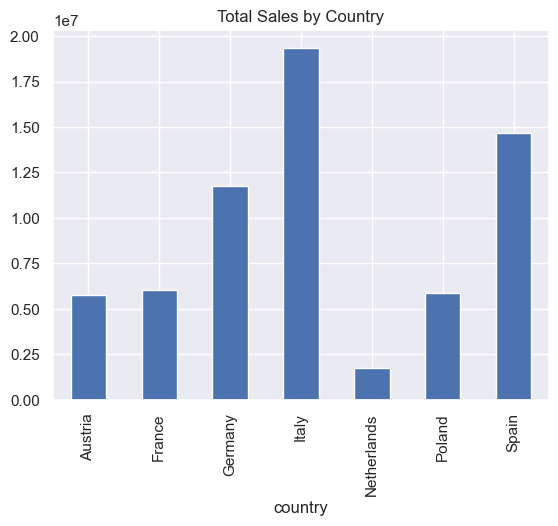

In [31]:
df.groupby('country')['units_sold'].sum().plot(kind='bar')
plt.title('Total Sales by Country')
plt.show()

Sales differ with different countries therefore location a demand driver

### Top 20 SKUs by revenue

In [7]:
sku_revenue = df.groupby(['country','sku_name','sku_id'])['net_sales'].sum().sort_values(ascending=False)
sku_top_revenue = sku_revenue[:20]
sku_top_revenue

country  sku_name           sku_id 
Italy    BrandD Cheese      SKU0064    4516984.50
Spain    BrandC Chips       SKU0027    4490597.37
Italy    BrandF Water       SKU0018    4366570.56
Spain    BrandF Water       SKU0018    4158905.52
Italy    BrandD Chips       SKU0028    3757276.30
         BrandA Toothpaste  SKU0097    3744669.01
         BrandB Chips       SKU0026    3702950.93
Germany  BrandC Chips       SKU0027    3674382.21
Italy    BrandA Cheese      SKU0061    3620259.00
         BrandD Milk        SKU0058    3603783.75
         BrandB Soap        SKU0092    3595710.15
         BrandE Soda        SKU0005    3517019.62
         BrandD Toothpaste  SKU0100    3465661.32
Germany  BrandF Water       SKU0018    3420040.80
Spain    BrandA Cheese      SKU0061    3416361.90
         BrandC Toothpaste  SKU0099    3409879.36
Italy    BrandC Toothpaste  SKU0099    3210460.88
         BrandC Chips       SKU0027    3157205.26
Germany  BrandB Soap        SKU0092    3113277.30
Italy    Brand

### ABC Classes by region

In [32]:
sku_sales = df.groupby(["country","sku_id"])["net_sales"].sum().reset_index()

sku_sales = sku_sales.sort_values(["country","net_sales"], ascending=[True, False])

sku_sales["cum_pct"] = sku_sales.groupby("country")["net_sales"].cumsum() / sku_sales.groupby("country")["net_sales"].transform("sum")

def abc(x):
    if x <= 0.7:
        return "A"
    elif x <= 0.9:
        return "B"
    else:
        return "C"

sku_sales["ABC_class"] = sku_sales["cum_pct"].apply(abc)

sku_sales

,country,sku_id,net_sales,cum_pct,ABC_class
20,Austria,SKU0027,1881904.66,0.043745,A
16,Austria,SKU0018,1690621.68,0.083043,A
69,Austria,SKU0092,1582125.30,0.119820,A
42,Austria,SKU0057,1448420.22,0.153488,A
45,Austria,SKU0061,1415742.30,0.186397,A
...,...,...,...,...,...
512,Spain,SKU0029,126754.01,0.996971,C
523,Spain,SKU0040,107463.63,0.997978,C
533,Spain,SKU0051,103232.16,0.998945,C
532,Spain,SKU0050,68680.00,0.999589,C


### Identify volatility (XYZ) by SKU

In [9]:
sku_vol = df.groupby(['sku_name',"sku_id"])["units_sold"].agg(["mean","std"]).reset_index()
sku_vol["cv"] = sku_vol["std"] / sku_vol["mean"]

def xyz(cv):
    if cv < 0.5:
        return "X"
    elif cv < 1:
        return "Y"
    else:
        return "Z"

sku_vol["XYZ_class"] = sku_vol["cv"].apply(xyz)

sku_vol.head()

,sku_name,sku_id,mean,std,cv,XYZ_class
0,BrandA Biscuits,SKU0037,84.247073,35.119650,0.416865,X
1,BrandA Cheese,SKU0061,88.853699,35.153635,0.395635,X
2,BrandA Chips,SKU0025,24.036115,10.046344,0.417969,X
3,BrandA Chocolate,SKU0031,43.371598,25.204041,0.581119,Y
4,BrandA Cleaner,SKU0079,92.448858,45.592056,0.493160,X


### Correlate price, promotions, and volume

              list_price  units_sold  discount_pct  promo_flag
list_price      1.000000   -0.082791     -0.042847   -0.047780
units_sold     -0.082791    1.000000      0.292777    0.295772
discount_pct   -0.042847    0.292777      1.000000    0.924791
promo_flag     -0.047780    0.295772      0.924791    1.000000


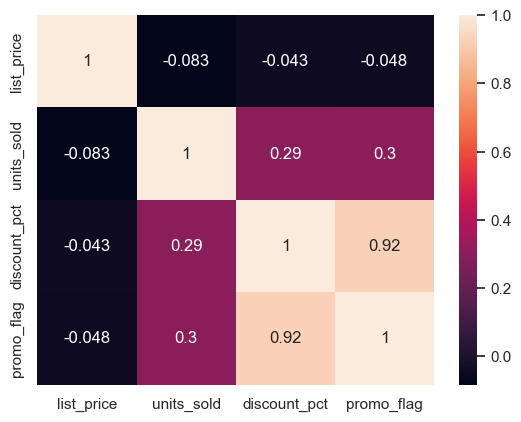

In [10]:
# Correlation 
df_corr = df[
    [
        'list_price', 'units_sold',
        'discount_pct', 'promo_flag'
    ]
].corr()
print(df_corr)
sns.heatmap(df_corr, annot=True)
plt.show()

###  Visualise seasonality


#### Monthly patterns

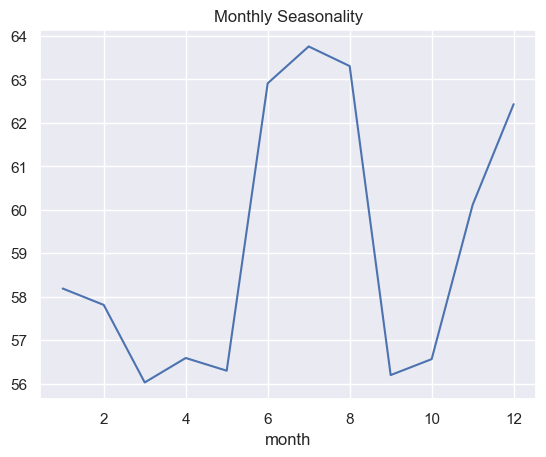

In [11]:
monthly = df.groupby('month')['units_sold'].mean()

monthly.plot(kind='line', title='Monthly Seasonality')
plt.show()

#### Weekly patterns

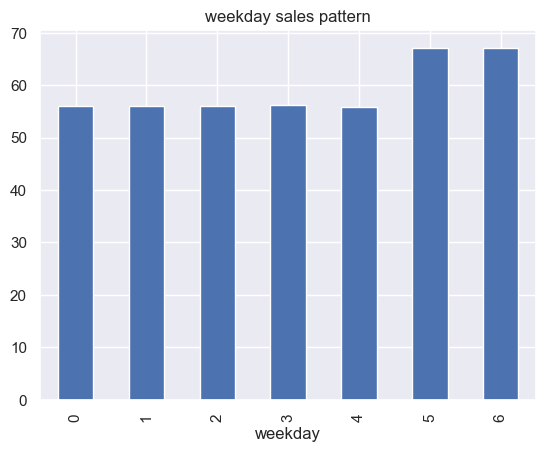

In [12]:
weekly = df.groupby('weekday')['units_sold'].mean()

weekly.plot(kind='bar', title='weekday sales pattern')
plt.show()

### Forecasting Statistics + Machine Learning)

#### Forecast 10 SKUs with different demand profiles

In [13]:
sku_profile = pd.merge(sku_sales, sku_vol, on='sku_id')
sku_profile = sku_profile.drop_duplicates(subset='sku_id')

In [14]:
selected_skus = []
groups = [
    ('A','x'), ('A','Y'),('A','Z'),
    ('B','X'), ('B','Y'), ('B','Z'),
    ('C','X'), ('C','Y'), ('C','Z')
]
for a, x in groups:
    subset = sku_profile[
        (sku_profile['ABC_class']==a) &\
        (sku_profile['XYZ_class']==x) ]
    if not subset.empty:
        sku = subset.iloc[0]['sku_id']
        if sku not in selected_skus:
            selected_skus.append(sku)
# If less than 10, fill randomly
remaining = sku_profile[~sku_profile['sku_id'].isin(selected_skus)]
selected_skus += list(remaining['sku_id'].head(10 - len(selected_skus)))
print(selected_skus)

['SKU0027', 'SKU0076', 'SKU0080', 'SKU0025', 'SKU0006', 'SKU0018', 'SKU0092', 'SKU0057', 'SKU0061', 'SKU0099']


## Time to Forecast
### Time series forecast

In [15]:
skus_df = df[df['sku_id'].isin(selected_skus)]
skus_df

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
4380,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.00,0,118.68,118.68,211,0,6,S024,0.94,0.275
4381,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.15,1,24.51,20.83,399,1,6,S004,0.70,0.305
4382,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.15,1,212.85,180.92,180,0,5,S032,0.58,0.397
4383,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.20,1,234.78,187.82,289,0,5,S055,0.94,0.070
4384,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.00,0,198.66,198.66,378,0,7,S037,0.93,0.278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1098280,2023-12-27,2023,12,27,52,2,0,0,13.03,5.99,...,0.00,0,164.54,164.54,307,0,7,S022,2.52,0.418
1098281,2023-12-28,2023,12,28,52,3,0,0,11.78,3.16,...,0.00,0,212.17,212.17,316,0,3,S057,2.26,0.478
1098282,2023-12-29,2023,12,29,52,4,0,0,15.16,5.27,...,0.20,1,389.70,311.76,284,0,8,S018,2.32,0.265
1098283,2023-12-30,2023,12,30,52,5,1,0,19.81,8.04,...,0.00,0,320.42,320.42,193,0,5,S011,2.73,0.370


In [16]:
skus_df.loc[:,'rolling_mean'] = skus_df['units_sold'].rolling(7).mean()
skus_df.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct,rolling_mean
4380,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0,118.68,118.68,211,0,6,S024,0.94,0.275,NaN
4381,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,1,24.51,20.83,399,1,6,S004,0.70,0.305,NaN
4382,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,1,212.85,180.92,180,0,5,S032,0.58,0.397,NaN
4383,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,1,234.78,187.82,289,0,5,S055,0.94,0.070,NaN
4384,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0,198.66,198.66,378,0,7,S037,0.93,0.278,NaN


In [17]:
#skus_df.loc[:, f'lag_{lag}'] = skus_df.groupby('sku_id')['units_sold'].shift(lag)

for lag in [1, 7, 14]:
    skus_df.loc[:, f'lag_{lag}'] = skus_df.groupby('sku_id')['units_sold'].shift(lag)
skus_df = skus_df.dropna()
skus_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 110455 entries, 4394 to 1098284
Data columns (total 37 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   date            110455 non-null  object 
 1   year            110455 non-null  int64  
 2   month           110455 non-null  int64  
 3   day             110455 non-null  int64  
 4   weekofyear      110455 non-null  int64  
 5   weekday         110455 non-null  int64  
 6   is_weekend      110455 non-null  int64  
 7   is_holiday      110455 non-null  int64  
 8   temperature     110455 non-null  float64
 9   rain_mm         110455 non-null  float64
 10  store_id        110455 non-null  object 
 11  country         110455 non-null  object 
 12  city            110455 non-null  object 
 13  channel         110455 non-null  object 
 14  latitude        110455 non-null  float64
 15  longitude       110455 non-null  float64
 16  sku_id          110455 non-null  object 
 17  sku_name   

In [18]:
skus_df.columns

Index(['date', 'year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend',
       'is_holiday', 'temperature', 'rain_mm', 'store_id', 'country', 'city',
       'channel', 'latitude', 'longitude', 'sku_id', 'sku_name', 'category',
       'subcategory', 'brand', 'units_sold', 'list_price', 'discount_pct',
       'promo_flag', 'gross_sales', 'net_sales', 'stock_on_hand',
       'stock_out_flag', 'lead_time_days', 'supplier_id', 'purchase_cost',
       'margin_pct', 'rolling_mean', 'lag_1', 'lag_7', 'lag_14'],
      dtype='object')

In [19]:
num_df = skus_df.select_dtypes(include=['int64','float64'])
num_df.columns

Index(['year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend',
       'is_holiday', 'temperature', 'rain_mm', 'latitude', 'longitude',
       'units_sold', 'list_price', 'discount_pct', 'promo_flag', 'gross_sales',
       'net_sales', 'stock_on_hand', 'stock_out_flag', 'lead_time_days',
       'purchase_cost', 'margin_pct', 'rolling_mean', 'lag_1', 'lag_7',
       'lag_14'],
      dtype='object')

In [20]:
features = ['year', 'month', 'day', 'weekofyear', 'weekday', 'is_weekend',
       'is_holiday', 'temperature', 'rain_mm', 'latitude', 'longitude',
       'list_price', 'discount_pct', 'promo_flag',
        'stock_on_hand', 'stock_out_flag', 'lead_time_days',
       'purchase_cost', 'margin_pct', 'rolling_mean', 'lag_1', 'lag_7',
       'lag_14']
X = skus_df[features]

y= skus_df['units_sold']

In [21]:
# importing packages essential for the forecast
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
# Initialize XGBoost model
model = xgb.XGBRegressor(
    n_estimators = 500, #number of trees
    learning_rate=0.05, # step size shrinkage
    max_depth = 6, #maximum depth of a tree
    subsample = 0.8, # stochastic gradient boosting
    colsample_bytree = 0.8, #fraction of features per tree
    random_state=42
)

In [24]:
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [25]:
y_pred = model.predict(X_test)
y_pred

array([ 37.959034, 110.407936, 194.18243 , ...,  94.788536, 199.68956 ,
        69.40035 ], dtype=float32)

In [26]:
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'RMSE: {rmse: .4f}')
print(f'MAE: {mae: .4f}')
print(f'R2 score: {r2: .4f}')

RMSE:  26.8789
MAE:  19.0745
R2 score:  0.7526


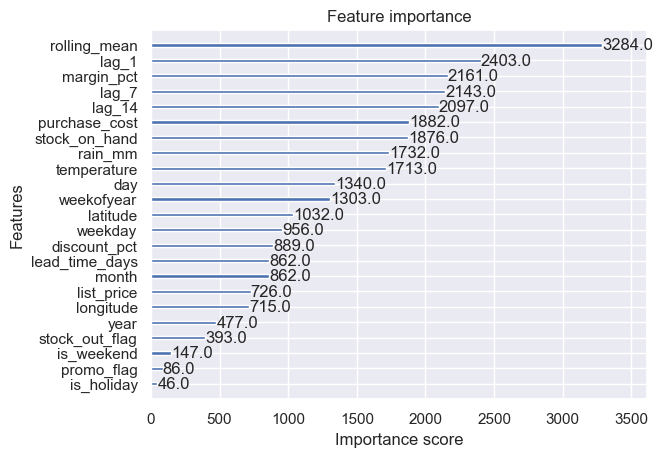

In [27]:
xgb.plot_importance(model)
plt.show()

In [30]:
print(len(y_test), len(y_pred))

22091 22091
